# Lab: foundation models for Australian tourism
Harsha Halgamuwe Hewage · AFRICAST 2026

**Task:** forecast quarterly Snowy Mountains holiday trips, using the same series as the ETS and ARIMA sessions. Values are **thousands of overnight trips**.

Follow the lecture's sequence: prepare the history, make a seasonal-naive forecast, try zero-shot models, measure errors, then compare fine-tuned forecasts. Work through the saved outputs first. The exercises are for independent study after the lecture.

## 1. Connect the concepts

### ETS: the same method can give different fitted models
Fit ETS to Snowy Mountains holiday trips, then fit ETS separately to Sydney holiday trips. The fitting method is the same, but each fitted model is learned from its own history. Its estimated level, seasonal pattern and other settings can differ. Automatic selection may also choose a different ETS form.

This is the familiar **local-model** workflow. Global models can share learning across several series. A foundation model brings learning from a broad collection: we supply our tourism history to a model that has already been trained, without fitting it from scratch.

### What is a foundation model?
A foundation model is trained on large, varied data so that it can be reused for a range of tasks and settings. The initial learning stage is **pretraining**. For time-series forecasting, we supply a new history to the pretrained model and ask for future values.

### Four characteristics
1. **Large, varied training data:** examples from many settings.
2. **Often many parameters:** learned numbers store the model's behaviour.
3. **Reusable across tasks:** the trained model can be applied to different series.
4. **Can be adapted:** further training can tailor it to our data, where the model interface supports this.

Model size does not guarantee accuracy, and fine-tuning may help or hurt. We will check both in the tourism example.

### Follow the tourism history through each model
**Weights** are numbers learned during training. For a zero-shot forecast, those numbers stay fixed while we supply the tourism history. Attention combines information across positions; feed-forward layers refine that information.

![Published TimeGPT-1 encoder-decoder architecture applied to tourism](figures/timegpt_architecture.png)

TimeGPT's encoder represents the historical values; the decoder uses that information, and a linear output layer maps to the requested horizon. This is the simplified published TimeGPT-1 architecture, not a description of undisclosed changes to the hosted service. [Architecture source](https://arxiv.org/html/2310.03589v3).

![Chronos-2 encoder-only architecture applied to tourism](figures/chronos2_architecture.png)

Chronos-2 scales the history and converts groups of observations (patches) into vectors. **Time attention** combines information across patches; **group attention** allows related series or predictors to share information when supplied. Our first example contains one series. A quantile output layer gives the median and values for the interval; scaling is reversed to return trips. The future trips remain unknown throughout prediction. [Architecture source](https://arxiv.org/html/2510.15821v1).

The Chronos-2 code maps to these steps:

| Call | What happens |
|---|---|
| `from_pretrained(...)` | Load the pretrained model and its weights. |
| `predict_df(history, ...)` | Turn the history into forecasts without training. |
| `fit(inputs=[...], ...)` | Adapt a copy of the model using historical training windows. |
| `adapted.predict_df(history, ...)` | Forecast with that adapted model. |

Before running code, explain:
1. What is learned during pretraining?
2. What changes in zero-shot inference?
3. What changes during fine-tuning?

<details><summary>Check your explanation</summary>
Pretraining estimates parameters from a source collection. Zero-shot inference changes the historical context while keeping those parameters fixed. Fine-tuning updates parameters or an adapter using target-task history. A pretrained model's broad usefulness must still be evaluated.
</details>

### Two common routes to pretrained forecasting
- **Built for time series:** TimeGPT, Chronos-2, TimesFM and Moirai learn from time-series collections. This lab demonstrates TimeGPT and Chronos-2.
- **Language models adapted for forecasting:** approaches such as PromptCast and Time-LLM reuse a pretrained language model, changing how time-series inputs and outputs are represented.

### Comparing the model families

| Model / version | Architecture | Input representation | Forecast output |
|---|---|---|---|
| TimeGPT-1 | Encoder-decoder transformer | Historical values and positions | Point forecasts and API intervals |
| Chronos-2 | Encoder-only transformer | Patches; optional predictors or related series | Quantiles |
| TimesFM 2.5 | Decoder-only transformer | Patches of historical values | Point forecasts and quantiles |
| Moirai 1.0 | Encoder-only transformer | Patches; optional predictors | Forecast distribution |
| Lag-Llama | Decoder-only transformer | Lagged values and time features | Forecast distribution |
| Tiny Time Mixers | MLP mixer | Patches; optional predictors in adaptation | Point forecasts |

The FoundationForecast `Chronos` wrapper defaults to original Chronos-T5; choose `amazon/chronos-2` explicitly for Chronos-2. TimesFM 2.5 can return point forecasts and quantiles using its optional quantile head; it is one supported version, not the latest release. Moirai 1.0 describes the original distribution-based model. Predictor support in the model does not guarantee the same support through every wrapper. Lag-Llama and Tiny Time Mixers are additional examples from FPP and are not listed in this API reference. The lab continues to use the direct Nixtla and Chronos APIs, including their fine-tuning examples.

### A related approach: tabular foundation models
TabPFN and TabICL are pretrained for table prediction, often using simulated tasks. In the standard in-context workflow, example rows with known outcomes and new rows with unknown outcomes enter the pretrained model together. Its weights stay fixed.

To use this idea for forecasting, represent each quarter as a row with time/calendar features and trips as the target. Historical trips supply the context; future trips stay missing. Keep the evaluation split in time. The optional slide illustrates this representation; this lab runs TimeGPT and Chronos-2 only.

**The name `fit` depends on the library:** TabICL's usual `fit` prepares context; the Chronos-2 `fit` below performs fine-tuning. Adding context rows is different from updating weights.

### Advantages and disadvantages
The slide uses the eight entries in Peixeiro Chapter 1, Table 1.1:

| Advantages | Disadvantages |
|---|---|
| Use out-of-the-box forecasting pipelines | Privacy concerns |
| Can generate forecasts with few data points | No control of model's capabilities |
| Require less forecasting expertise | May not be optimal for every use case |
| Reusable across tasks | High resource requirements |

These benefits make it easier to start; they do not establish forecast accuracy. Capabilities depend on the model/version, and privacy and resource needs depend on how it is run.

### Challenges of building the pretrained model
1. Generalising across frequencies and domains.
2. Supporting different horizons: one week is 7 daily steps or 168 hourly steps.
3. Obtaining the computing resources for large-scale training.
4. Finding and combining enough varied, open time-series data.

These follow Section 2.9 of the supplied Chapter 2. We reuse pretrained weights here; we do not build a foundation model from scratch.

## 2. Environment and execution choices
Open this notebook with `exercises/foundation_models` as the working directory. For a lightweight cached run:
```
python -m pip install numpy pandas matplotlib notebook
```
For live model runs, use a separate Python 3.12 environment and `python -m pip install -r requirements.txt`. Download `amazon/chronos-2` before working offline. Keep `NIXTLA_API_KEY` in the environment or your own local `.env`; never put its value in this notebook.

Leave all switches below `False` to reproduce the saved walkthrough. To run only one model, enable its switch. Fine-tuning also requires `RUN_FINETUNING=True`:

| Run | Switches to enable |
|---|---|
| Chronos-2 zero-shot | `RUN_CHRONOS` |
| Chronos-2 plus LoRA | `RUN_CHRONOS`, `RUN_FINETUNING` |
| TimeGPT zero-shot | `RUN_TIMEGPT` |
| TimeGPT plus adaptation | `RUN_TIMEGPT`, `RUN_FINETUNING` |
| Optional Chronos validation | `RUN_CHRONOS`, `RUN_VALIDATION` |
| Optional calendar predictor call | `RUN_CHRONOS`, `RUN_COVARIATES` |

After changing switches, restart the kernel and run all cells from the top. Saved-result branches are labelled, so a loaded result is not mistaken for a new model run.



In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
assert (ROOT / "data/tourism.csv").exists(), "Open from exercises/foundation_models."
RUN_CHRONOS = False
RUN_TIMEGPT = False
RUN_FINETUNING = False
RUN_COVARIATES = False
RUN_VALIDATION = False
pd.set_option("display.float_format", lambda value: f"{value:.2f}")
REGION, PURPOSE = "Snowy Mountains", "Holiday"
H = 4

## 3. Prepare the same tourism series
The workshop CSV contains quarterly series indexed by region, state and travel purpose. The model interface calls the identifier `unique_id`, the date `ds`, and the target `y`.

The matching R selection is:
```r
tourism |> filter(Region == "Snowy Mountains", Purpose == "Holiday")
```

In [2]:
tourism = pd.read_csv(ROOT / "data/tourism.csv", parse_dates=["Quarter"])
df = tourism.loc[(tourism.Region == REGION) & (tourism.Purpose == PURPOSE)].copy()
df = df.rename(columns={"Quarter": "ds", "Trips": "y"})
df["unique_id"] = REGION + " / " + PURPOSE
df = df[["unique_id", "ds", "y"]].sort_values("ds").reset_index(drop=True)
assert df.unique_id.nunique() == 1 and len(df) == 80
assert not df.duplicated(["unique_id", "ds"]).any()
assert df[["ds", "y"]].notna().all().all()
assert df.ds.equals(pd.Series(pd.date_range(df.ds.iloc[0], periods=len(df), freq="QS")))
display(df.head())
print(len(tourism), "raw rows;", len(df), "quarters in the selected series")

,unique_id,ds,y
0,Snowy Mountains / Holiday,1998-01-01,101.15
1,Snowy Mountains / Holiday,1998-04-01,112.42
2,Snowy Mountains / Holiday,1998-07-01,310.19
3,Snowy Mountains / Holiday,1998-10-01,89.83
4,Snowy Mountains / Holiday,1999-01-01,112.38


24320 raw rows; 80 quarters in the selected series


## 4. Define the forecasting experiment
- Initial training: 1998 Q1–2013 Q4 (64 quarters).
- Validation: three non-overlapping four-quarter windows in 2014–2016.
- Final history: observations through 2016 Q4 (76 quarters).
- Final test: the four quarters of 2017.

The fine-tuning settings are fixed teaching settings. Both adaptation examples use the final history, never the 2017 targets. A fuller tuning exercise would choose settings using only earlier validation periods.

,part,quarters,start,end
0,initial training,64,1998-01-01,2013-10-01
1,validation,12,2014-01-01,2016-10-01
2,final test,4,2017-01-01,2017-10-01


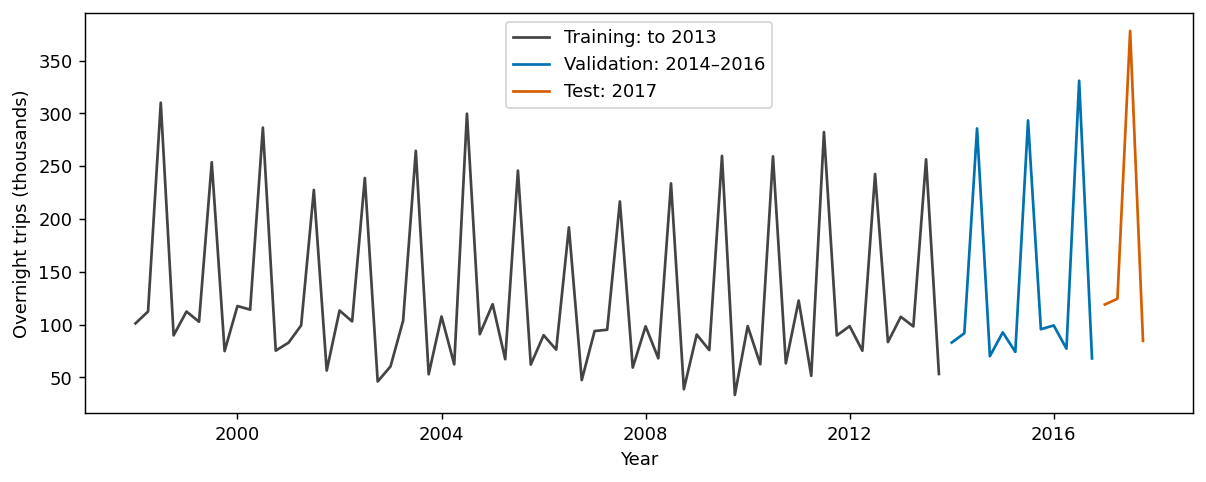

In [3]:
train, validation = df.iloc[:-4*H].copy(), df.iloc[-4*H:-H].copy()
history, test = df.iloc[:-H].copy(), df.iloc[-H:].copy()
display(pd.DataFrame({"part":["initial training","validation","final test"],
    "quarters":[len(train),len(validation),len(test)],
    "start":[train.ds.min(),validation.ds.min(),test.ds.min()],
    "end":[train.ds.max(),validation.ds.max(),test.ds.max()]}))
fig, ax = plt.subplots(figsize=(11,4))
for part,label,color in [(train,"Training: to 2013","#444444"),
                         (validation,"Validation: 2014–2016","#0072B2"),
                         (test,"Test: 2017","#D55E00")]:
    ax.plot(part.ds,part.y,label=label,color=color)
ax.set(ylabel="Overnight trips (thousands)",xlabel="Year")
ax.legend(); plt.show()

**Exercise:** identify the seasonal period and forecast horizon. Why would using the 2017 trips to select fine-tuning settings invalidate the final test?

<details><summary>Answer</summary>
The seasonal period and horizon are both four quarters. Selecting settings against 2017 reuses the test as validation, making the reported test performance optimistic as an estimate of performance on genuinely unexamined targets.
</details>

In [4]:
def cached(name):
    path = ROOT / "results" / (name + ".csv")
    if not path.exists():
        print("No saved", name, "forecast; use the live cell when access is available.")
        return None
    fc = pd.read_csv(path,parse_dates=["ds"])
    if set(fc.unique_id) != set(df.unique_id):
        print("No saved", name, "forecast for this series; enable a fresh run.")
        return None
    print("Loaded saved forecast:", name)
    return fc

def normalise(raw,point,lower,upper):
    return raw.rename(columns={point:"prediction",lower:"lower80",upper:"upper80"})

def evaluate(fc, actual=test, metric="MAE"):
    out = actual.merge(fc[["unique_id","ds","prediction"]],
        on=["unique_id","ds"],validate="one_to_one")
    assert len(out)==len(actual), "Forecast dates do not match the evaluation period."
    assert np.isfinite(out[["y", "prediction"]].to_numpy()).all(), "Missing or non-finite values."
    errors = out.y-out.prediction
    if metric == "RMSE": return np.sqrt((errors**2).mean())
    if metric != "MAE": raise ValueError("Use MAE or RMSE")
    return errors.abs().mean()

def plot_forecast(fc,label,reference=None,reference_label="Seasonal naive"):
    if fc is None: return
    fig,ax=plt.subplots(figsize=(11,4))
    ax.plot(history.ds.tail(16),history.y.tail(16),color="#555555",label="History")
    ax.plot(test.ds,test.y,"o-",color="black",label="Observed 2017")
    colour = "#D55E00" if ("LoRA" in label or "adapted" in label) else "#0072B2"
    if label == "Seasonal naive": colour = "#666666"
    ax.plot(fc.ds,fc.prediction,"o-",color=colour,label=label)
    if reference is not None:
        reference_colour = "#666666" if reference_label == "Seasonal naive" else "#0072B2"
        ax.plot(reference.ds,reference.prediction,"o--",color=reference_colour,label=reference_label)
    if "lower80" in fc:
        ax.fill_between(fc.ds,fc.lower80,fc.upper80,alpha=.2,color=colour,label="80% interval")
    ax.set(ylabel="Overnight trips (thousands)",xlabel="Year")
    ax.legend(); plt.show()

## 5. Seasonal-naive benchmark
Repeat the latest four quarters. This is the quarterly analogue of the seasonal-naive methods already used in the workshop.

The four values below match the seasonal-naive slide. Each is last year's observation for the same quarter. We will compare every model on these same four dates.

Forecasts for Q1–Q4: [99.21, 77.21, 330.99, 67.95]


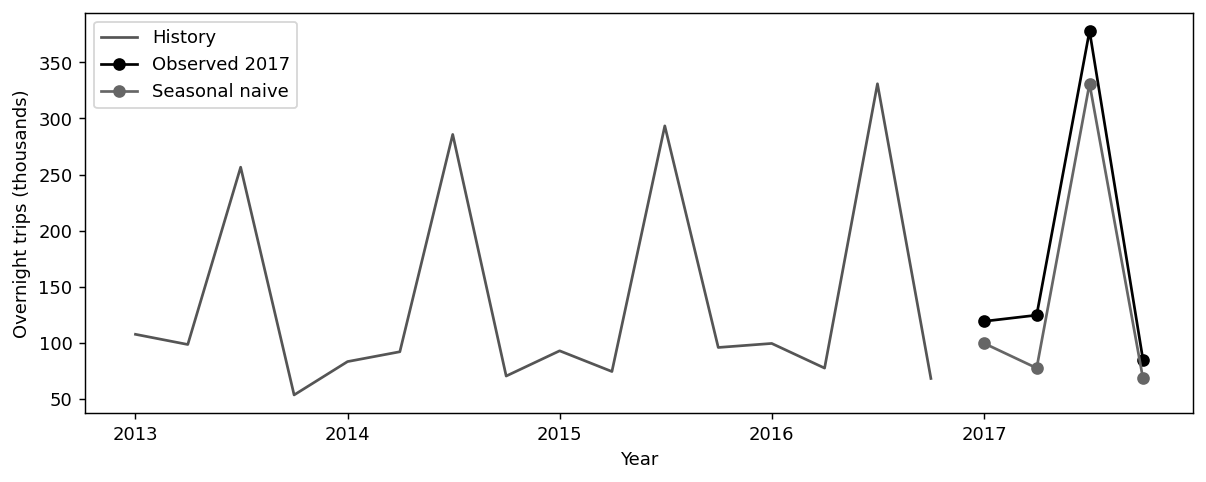

MAE: 32.73; RMSE: 35.80


In [5]:
baseline = test[["unique_id", "ds"]].copy()
baseline["prediction"] = history.y.tail(H).to_numpy()
print("Forecasts for Q1–Q4:", baseline.prediction.round(2).tolist())
plot_forecast(baseline, "Seasonal naive")
print(f"MAE: {evaluate(baseline):.2f}; RMSE: {evaluate(baseline, metric='RMSE'):.2f}")

## 6. Zero-shot TimeGPT
Send `history` to Nixtla's hosted model and request four future quarters. The service runs the model; we receive a forecast table.

- `h=H`: four quarters ahead.
- `freq="QS"`: dates mark the start of each quarter.
- `level=[80]`: request an 80% prediction interval.
- `finetune_steps=0`: use the pretrained model without adaptation.

With `RUN_TIMEGPT=False`, the cell looks for a saved forecast. None is included because the saved request returned a quota error. With `True`, the cell makes a new request using your locally configured key. A failure leaves this model out of the results table.

In [6]:
timegpt = None
if RUN_TIMEGPT:
    from dotenv import load_dotenv
    from nixtla import NixtlaClient
    load_dotenv(ROOT / ".env")
    assert os.getenv("NIXTLA_API_KEY"), "Configure the key locally."
    client=NixtlaClient(max_retries=1)
    try:
        raw=client.forecast(df=history,h=H,freq="QS",level=[80],finetune_steps=0)
        timegpt=normalise(raw,"TimeGPT","TimeGPT-lo-80","TimeGPT-hi-80")
    except Exception as exc:
        print("TimeGPT unavailable:",type(exc).__name__,"; check account access/quota.")
else:
    timegpt=cached("timegpt")
if timegpt is not None:
    display(timegpt[["ds", "prediction", "lower80", "upper80"]].round(2))
    plot_forecast(timegpt,"TimeGPT",reference=baseline)

No saved timegpt forecast; use the live cell when access is available.


## 7. Zero-shot Chronos-2
Load `amazon/chronos-2`, then pass exactly the same history and horizon. `predict_df` runs the architecture shown above; it does not update the weights.

The API returns quantile columns named `"0.1"`, `"0.5"` and `"0.9"`. The shared plotting and scoring helpers rename them to `lower80`, `prediction` and `upper80`. We use the median (`0.5`) as the point forecast.

First read the four-row table, then examine the plot. The table uses the same quantile column names as the slide.

Loaded saved forecast: chronos2


,ds,0.1,0.5,0.9
0,2017-01-01,87.67,110.23,136.42
1,2017-04-01,64.07,85.74,110.65
2,2017-07-01,247.12,278.78,311.71
3,2017-10-01,52.49,74.47,97.20


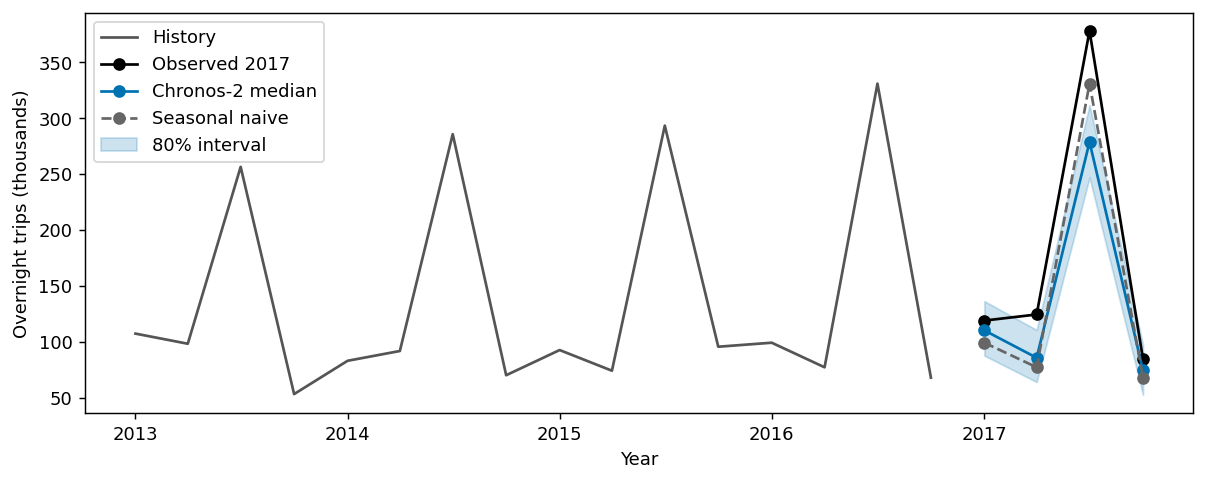

In [7]:
pipeline=None
if RUN_CHRONOS:
    import torch
    from chronos import Chronos2Pipeline
    torch.set_num_threads(4); torch.manual_seed(42)
    pipeline=Chronos2Pipeline.from_pretrained("amazon/chronos-2",device_map="cpu")
    raw=pipeline.predict_df(history,prediction_length=H,quantile_levels=[.1,.5,.9],
        id_column="unique_id",timestamp_column="ds",target="y")
    chronos=normalise(raw,"0.5","0.1","0.9")
else:
    chronos=cached("chronos2")
assert chronos is not None, "Enable RUN_CHRONOS for this series, or restore the Snowy Mountains example."
# Show the same columns as the slide, without the saved observed targets.
output_table = chronos.rename(columns={"lower80": "0.1", "prediction": "0.5", "upper80": "0.9"})
display(output_table[["ds", "0.1", "0.5", "0.9"]].round(2))
plot_forecast(chronos, "Chronos-2 median", reference=baseline)

The July row is the third quarter: the median forecast is about **278.78 thousand trips**, with an interval from **247.12 to 311.71 thousand**. The observed winter peak was higher. The next step puts a number on those misses.

## 8. Uncertainty and evaluation
MAE is the average absolute miss. RMSE gives large misses more weight. Both are measured in thousands of trips. We keep MAE as the main measure for our median forecasts and also report RMSE.

As in the slide, match each forecast to its observed quarter, calculate the errors, then calculate the two scores. The helper `evaluate` performs this same calculation for the other models. [More on accuracy measures](https://otexts.com/fpppy/05-toolbox.html#evaluating-point-forecast-accuracy).

The 0.1 and 0.9 quantiles form a nominal 80% prediction interval. Count how many observations it contains, but remember that four quarters are too few to assess long-run coverage.

In [8]:
checked = test.merge(chronos[["unique_id", "ds", "prediction", "lower80", "upper80"]],
                     on=["unique_id", "ds"], validate="one_to_one")
assert len(checked) == H
errors = checked["y"] - checked["prediction"]
mae = errors.abs().mean()
rmse = np.sqrt((errors ** 2).mean())
print(f"MAE: {mae:.2f}; RMSE: {rmse:.2f}")
print("Covered quarters:", checked.y.between(checked.lower80, checked.upper80).sum(), "of", H)

MAE: 39.27; RMSE: 53.75
Covered quarters: 2 of 4


### Check earlier forecast periods before choosing settings
Before trying adaptation, check the zero-shot forecasts on earlier years. This is the validation step in the slides. Keep 2017 separate when choosing settings.

The saved validation results cover three four-quarter forecasts: 2014 using data through 2013, 2015 using data through 2014, and 2016 using data through 2015. The table pools those 12 errors. It is separate from the four-quarter final-test scores calculated above.

Enable `RUN_VALIDATION` and `RUN_CHRONOS` for a fresh zero-shot validation run. The loop passes only data available at each forecast origin. To tune LoRA, repeat this process for each candidate setting, starting with the pretrained model and fitting only that origin's context; then choose a setting before evaluating 2017.

In [9]:
if RUN_VALIDATION and RUN_CHRONOS:
    scores = []
    for end in range(len(train), len(history), H):
        context, actual = df.iloc[:end], df.iloc[end:end+H]
        raw = pipeline.predict_df(context, prediction_length=H, quantile_levels=[.1, .5, .9],
            id_column="unique_id", timestamp_column="ds", target="y")
        fc = normalise(raw, "0.5", "0.1", "0.9")
        scores.append({"cutoff": context.ds.iloc[-1], "MAE": evaluate(fc, actual),
                       "RMSE": evaluate(fc, actual, metric="RMSE")})
    display(pd.DataFrame(scores).round(2))
elif (REGION, PURPOSE) == ("Snowy Mountains", "Holiday"):
    rows = []
    for label, name in [("Seasonal naive", "seasonal_naive_validation"), ("Chronos-2", "chronos2_validation")]:
        fc = cached(name)
        rows.append({"model": label, "quarters": len(fc), "MAE": evaluate(fc, validation),
                     "RMSE": evaluate(fc, validation, metric="RMSE")})
    display(pd.DataFrame(rows).round(2))
else:
    print("No saved validation for this series. Enable a fresh validation run.")

Loaded saved forecast: seasonal_naive_validation
Loaded saved forecast: chronos2_validation


,model,quarters,MAE,RMSE
0,Seasonal naive,12,17.68,20.65
1,Chronos-2,12,18.45,23.13


**Exercise:** which model has the smaller validation MAE? Does the ranking on this series establish a generally better method?

<details><summary>Answer</summary>
Seasonal naive has validation MAE about 17.68 thousand trips, compared with 18.45 for Chronos-2. This is one series and a small set of origins. It does not establish a universal ranking; public-data overlap with pretraining is also unknown.
</details>

## 9. Fine-tuning TimeGPT
Now adapt the model using the **same 76 historical quarters**, then forecast the same four quarters of 2017. Only the adaptation arguments change.

| Argument | Meaning |
|---|---|
| `finetune_steps=10` | Ten training updates, not ten future quarters. |
| `finetune_depth=1` | The smallest adaptation depth on the API's 1–5 scale. |
| `finetune_loss="mae"` | Use absolute forecast errors during adaptation. |

Set both `RUN_TIMEGPT` and `RUN_FINETUNING` to `True`. First obtain the zero-shot forecast, so the comparison has a baseline. These are fixed teaching settings, not settings selected using 2017.

If both requests succeed, the cell shows the adapted forecast and a before/after error table. If access is unavailable, it reports that status and makes no claim about improvement.

In [10]:
timegpt_ft=None
if RUN_FINETUNING and RUN_TIMEGPT:
    if timegpt is None:
        print("Skipped adaptation: obtain the zero-shot TimeGPT forecast first.")
    else:
        try:
            raw=client.forecast(df=history,h=H,freq="QS",level=[80],
                finetune_steps=10,finetune_depth=1,finetune_loss="mae")
            timegpt_ft=normalise(raw,"TimeGPT","TimeGPT-lo-80","TimeGPT-hi-80")
        except Exception as exc:
            print("TimeGPT adaptation unavailable:",type(exc).__name__)
else:
    timegpt_ft=cached("timegpt_finetuned")
if timegpt_ft is not None:
    display(timegpt_ft[["ds", "prediction", "lower80", "upper80"]].round(2))
    plot_forecast(timegpt_ft, "TimeGPT adapted", reference=timegpt, reference_label="TimeGPT zero-shot")
    if timegpt is not None:
        display(pd.DataFrame([
            {"model": label, "MAE": evaluate(fc), "RMSE": evaluate(fc, metric="RMSE")}
            for label, fc in [("TimeGPT zero-shot", timegpt), ("TimeGPT adapted", timegpt_ft)]
        ]).round(2))

No saved timegpt_finetuned forecast; use the live cell when access is available.


## 10. Fine-tuning Chronos-2 with LoRA
LoRA (low-rank adaptation) learns a small set of added weights while keeping the original weights fixed. `fit` returns an adapted model; we then call `adapted.predict_df` to forecast.

Only the 76 pre-2017 observations enter `fit`. Training examples are historical windows and the values that followed them within this history. The four 2017 observations are used later for evaluation.

| Setting | Meaning |
|---|---|
| `prediction_length=H` | Train to forecast four steps ahead. |
| `context_length=64` | Allow up to 64 past observations per training example. |
| `min_past=8` | Require at least eight past observations in a training example. |
| `num_steps=10` | Make ten training updates. |
| `learning_rate=1e-5` | Control the size of each update. |
| `batch_size=4` | Process four training examples per batch. |

Set `RUN_CHRONOS=True` and `RUN_FINETUNING=True` for a new run. Otherwise, read the saved adapted forecast. The dictionary `lora_settings` collects the fixed training details. The two calls below match the slides: **adapt**, then **forecast**. Ten steps demonstrate the process; they are not a recommended optimum.

Loaded saved forecast: chronos2_finetuned


,ds,prediction,lower80,upper80
0,2017-01-01,107.52,78.85,134.14
1,2017-04-01,79.17,49.73,107.50
2,2017-07-01,273.43,237.61,319.89
3,2017-10-01,71.97,54.61,101.82


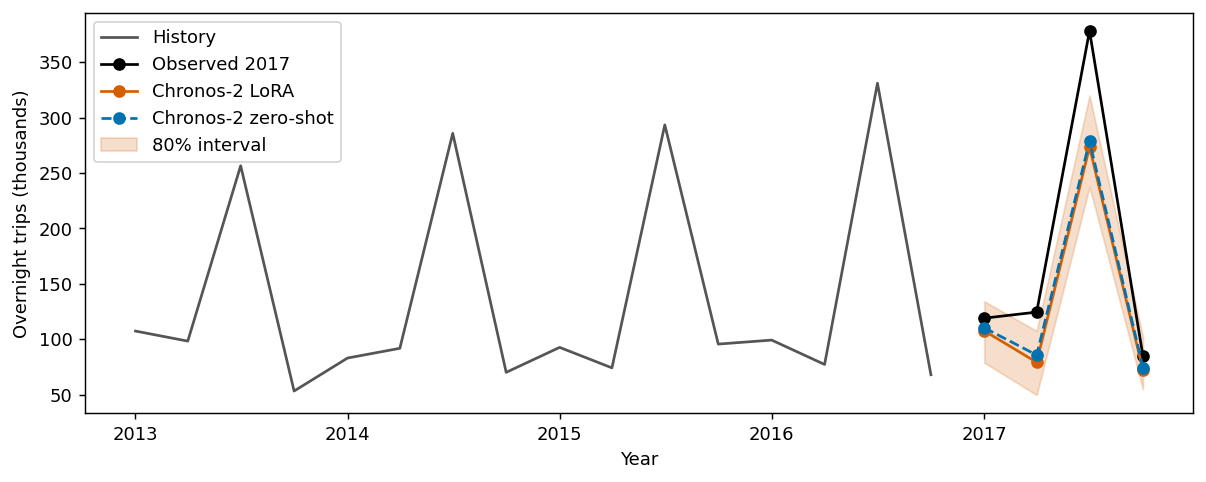

In [11]:
if RUN_FINETUNING and RUN_CHRONOS:
    import peft  # Required: do not silently fall back to full fine-tuning.
    import torch
    from chronos import Chronos2Pipeline
    torch.set_num_threads(4); torch.manual_seed(42)
    if pipeline is None:
        pipeline=Chronos2Pipeline.from_pretrained("amazon/chronos-2",device_map="cpu")
    lora_settings = dict(
        context_length=64, min_past=8, learning_rate=1e-5, batch_size=4,
        output_dir="tmp/chronos2_lora", report_to="none",
        dataloader_num_workers=0, optim="adamw_torch", seed=42,
    )
    adapted = pipeline.fit(
        inputs=[history.y.to_numpy(dtype=np.float32)], prediction_length=H,
        finetune_mode="lora", num_steps=10, **lora_settings,
    )
    raw=adapted.predict_df(history,prediction_length=H,quantile_levels=[.1,.5,.9],
        id_column="unique_id",timestamp_column="ds",target="y")
    chronos_ft=normalise(raw,"0.5","0.1","0.9")
else:
    chronos_ft=cached("chronos2_finetuned")
if chronos_ft is not None:
    display(chronos_ft[["ds", "prediction", "lower80", "upper80"]].round(2))
    plot_forecast(chronos_ft, "Chronos-2 LoRA", reference=chronos, reference_label="Chronos-2 zero-shot")

In [12]:
rows=[]
for label,fc in [("Seasonal naive",baseline),("Chronos-2",chronos),("Chronos-2 LoRA",chronos_ft),
                 ("TimeGPT",timegpt),("TimeGPT adapted",timegpt_ft)]:
    if fc is not None: rows.append({"model":label,"MAE":evaluate(fc),"RMSE":evaluate(fc, metric="RMSE")})
display(pd.DataFrame(rows).round(2))

,model,MAE,RMSE
0,Seasonal naive,32.73,35.80
1,Chronos-2,39.27,53.75
2,Chronos-2 LoRA,43.55,57.68


The plot compares the original and adapted forecasts. The table matches the slide **Results on the held-out tourism year**. In the saved run, seasonal naive has the lowest MAE and RMSE. Chronos-2 LoRA still misses the winter peak and has larger errors than the original forecast.

**Exercise:** describe what the adaptation changed. Would you increase the training steps after inspecting the 2017 error?

<details><summary>Answer</summary>
MAE increases from 39.27 to 43.55 thousand trips, and RMSE from 53.75 to 57.68. This adaptation did not help on these four quarters. Assess other settings on earlier validation periods; using 2017 to choose settings would turn the final test into a tuning set.
</details>

## 11. Known-future predictors
So far, the model has used only past trips. We can also supply information known when making the forecast. Calendar quarters are known for 2017; realised weather and future trips are not.

The next cell encodes the quarter using a sine/cosine pair, which preserves the repeating yearly cycle. `history_x` contains historical targets and features. `future_x` contains dates and calendar features, **without future trips**. The API receives it through the `future_df` argument, as described on the slide.

The saved output shows the future feature table. Set `RUN_CHRONOS` and `RUN_COVARIATES` to `True` to make a forecast with it. This demonstrates the interface; no saved accuracy gain is claimed.

In [13]:
def calendar_features(frame):
    out=frame.copy()
    q=out.ds.dt.quarter
    out["quarter_sin"]=np.sin(2*np.pi*q/4)
    out["quarter_cos"]=np.cos(2*np.pi*q/4)
    return out

history_x=calendar_features(history)
future_x=pd.DataFrame({"unique_id":history.unique_id.iloc[0],
    "ds":pd.date_range(history.ds.iloc[-1],periods=H+1,freq="QS")[1:]})
future_x=calendar_features(future_x)
assert "y" not in future_x
display(future_x)

if RUN_COVARIATES and RUN_CHRONOS:
    with_calendar=pipeline.predict_df(history_x,future_df=future_x,
        prediction_length=H,quantile_levels=[.1,.5,.9],
        id_column="unique_id",timestamp_column="ds",target="y")
    plot_forecast(normalise(with_calendar,"0.5","0.1","0.9"),"Chronos-2 with calendar")

,unique_id,ds,quarter_sin,quarter_cos
0,Snowy Mountains / Holiday,2017-01-01,1.00,0.00
1,Snowy Mountains / Holiday,2017-04-01,0.00,-1.00
2,Snowy Mountains / Holiday,2017-07-01,-1.00,-0.00
3,Snowy Mountains / Holiday,2017-10-01,-0.00,1.00


## 12. Extend the study
1. Select another region and travel purpose. Enable fresh runs: saved outputs are specific to Snowy Mountains holiday trips.
2. Keep a final test and choose settings on earlier origins.
3. Compare seasonal naive, a classical model from the R sessions, and a foundation model.
4. Explain the seasonal pattern, point accuracy, interval behaviour and practical execution requirements.
5. If using multiple series, construct a distinct identifier for every region/state/purpose and evaluate each series on aligned dates.

## References and limitations
- [FPP Python Chapter 15](https://otexts.com/fpppy/15-foundation-models.html).
- Peixeiro, *Time Series Forecasting Using Foundation Models*, Chapters 1 and 2.
- Christoph Bergmeir, *Forecasting for Data Scientists*, Theory Session 2 (2025), especially pages 71 and 81–82.
- Christoph Molnar, *Tabular Foundation Models* (2026), Chapters 3–4 and 9.
- [Chronos](https://github.com/amazon-science/chronos-forecasting), [Nixtla](https://www.nixtla.io/docs), [Moirai](https://github.com/SalesforceAIResearch/uni2ts), [TimesFM](https://github.com/google-research/timesfm).
- [Tourism data documentation](https://tsibble.tidyverts.org/reference/tourism.html). The workshop CSV used here has 80 quarters ending in 2017 Q4.

These are teaching results on one public series. Pretraining overlap is unknown. Four test quarters are insufficient for general ranking or calibration conclusions. Settings and versions are recorded under `results/`.

## 13. Read the closing WP3 example

The lecture finishes with **overall Lao multi-domain RMSSE versus runtime**. It covers 20,736 monthly product-location series across five clinical domains, with horizons of 1, 3 and 6 months. These are separate research results; the tourism notebook does not rerun the WP3 experiment.

**RMSSE** divides RMSE by a scale derived from historical seasonal changes, allowing comparison across differently scaled series. Lower is better. The study excludes undefined zero-scale scores. This differs from the unscaled MAE and RMSE used for tourism.

![Overall Lao RMSSE versus runtime](figures/wp3/lao_runtime_rmsse.png)

This uses the original figure's RMSSE panels and model legend. The sPIN panels are left out. Read lower as more accurate and further left as faster. Chronos-2-FT-Full has the lowest aggregate mean RMSSE at all three horizons shown. It uses pooled full-weight adaptation for 1,000 steps, not the ten-step LoRA example in this lab. The figure follows the source's displayed model subset, excluding LightGBM and XGBoost variants.

Runtime covers the complete rolling-origin evaluation workload, including fitting/tuning/adaptation where applicable. TimeGPT runs remotely, so its elapsed time is not local CPU compute. These are overall Lao runtimes, not separately measured runtimes for individual clinical domains. Lao family-planning data informed model selection; this is not an unseen-country test.

**Reflection:** compare Chronos-2-FT-Full with Chronos-2, AutoETS and DeepAR. How much additional computation would an accuracy improvement justify in your setting?

<details><summary>Optional: the larger family-planning comparison</summary>

The larger overall FP figure is in the slide appendix. It covers 4,451 series from Côte d'Ivoire, Lao and Pakistan. The display boundary is widened slightly to reveal legend text clipped in the source PDF; the plotted content is unchanged.

![Overall FP RMSSE versus runtime](figures/wp3/fp_runtime_rmsse_display.png)

</details>

**Reference:** Harsha Chamara Hewage, Bahman Rostami-Tabar, Aris Syntetos and Federico Liberatore. *Foundation models in low-resource settings: Evaluating AI-driven forecasting in global health supply chains*.
